# 1) mount Drive

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2) import libraries

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3) Linreg(Low speed)

In [32]:
'''

    TEMPLATE FOR MACHINE LEARNING HOMEWORK

'''
import numpy as np
from numpy import linalg as LA
import matplotlib.pyplot as plt


class LinearRegression:

    def __init__(self, init_theta=None, alpha=0.01, n_iter=100):
        '''
        Constructor
        '''
        self.alpha = alpha
        self.n_iter = n_iter
        self.theta = init_theta
        self.JHist = None

    def gradientDescent(self, X, y, theta):
        '''
        Fits the model via gradient descent
        Arguments:
            X is a n-by-d numpy matrix
            y is an n-dimensional numpy vector
            theta is a d-dimensional numpy vector
        Returns:
            the final theta found by gradient descent
        '''
        n,d = X.shape
        self.JHist = []
        for i in range(self.n_iter):
            self.JHist.append((self.computeCost(X, y, theta), theta))
            print("Iteration: ", i+1, " Cost: ", self.JHist[i][0], " Theta: ", theta)
            # TODO:  add update equation here
            ##################################
            list_of_gradients = []
            for i in range(X.shape[0]):
              yp = np.dot(X[i],theta)
              error = yp - y[i]
              list_of_gradients.append(np.dot(X[i].T,error))
            theta = theta - (self.alpha/n) * sum(list_of_gradients)
            ##################################

        return theta

    def computeCost(self, X, y, theta):
        '''
        Computes the objective function
        Arguments:
          X is a n-by-d numpy matrix
          y is an n-dimensional numpy vector
          theta is a d-dimensional numpy vector
        Returns:
          a scalar value of the cost
              ** make certain you don't return a matrix with just one value! **
        '''
        # TODO: add objective (cost) equation here
        ###########################################
        m = X.shape[0]
        error_values = []
        for i in range(m):
          y_pred = np.dot(X[i],theta)
          error_values.append((y_pred - y[i])**2)
        error = sum(error_values)
        cost = (1/(2*m))*(error)
        return cost.item()
        ###########################################

    def fit(self, X, y):
        '''
        Trains the model
        Arguments:
            X is a n-by-d numpy matrix
            y is an n-dimensional numpy vector
        '''
        n = len(y)
        n,d = X.shape
        if self.theta is None:
            self.theta = np.matrix(np.zeros((d,1)))
        self.theta = self.gradientDescent(X,y,self.theta)

    def predict(self, X):
        '''
        Used the model to predict values for each instance in X
        Arguments:
            X is a n-by-d numpy matrix
        Returns:
            an n-dimensional numpy vector of the predictions
        '''
        # TODO:  add prediction function here
        ########################################
        predictions = []
        for i in range(len(X)):
          predictions.append(X[i].dot(self.theta))
        return predictions
        ########################################

#TEST UNIVARIATE (low speed)
TEST SCRIPT FOR UNIVARIATE LINEAR REGRESSION

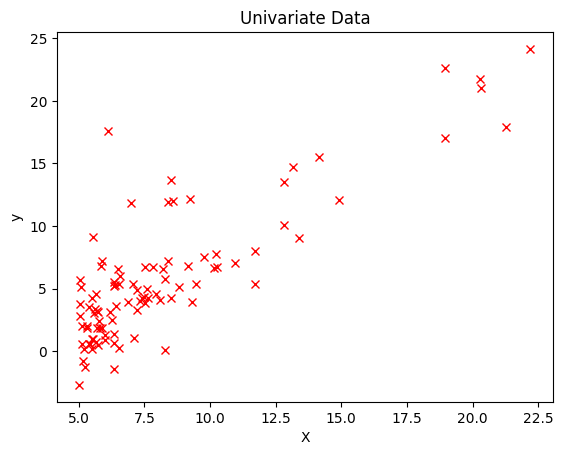

Iteration:  1  Cost:  4256.570027009517  Theta:  [[10.]
 [10.]]
Iteration:  2  Cost:  153.41562305090963  Theta:  [[9.14241135]
 [1.69691422]]
Iteration:  3  Cost:  23.704502028188667  Theta:  [[8.97091378]
 [0.22284515]]
Iteration:  4  Cost:  19.55335965069969  Theta:  [[ 8.92141228]
 [-0.03727971]]
Iteration:  5  Cost:  19.370068821014623  Theta:  [[ 8.89363145]
 [-0.08161346]]
Iteration:  6  Cost:  19.31234880158314  Theta:  [[ 8.86974598]
 [-0.08759093]]
Iteration:  7  Cost:  19.258783829512495  Theta:  [[ 8.84658712]
 [-0.08675349]]
Iteration:  8  Cost:  19.205536524093187  Theta:  [[ 8.82359151]
 [-0.08470805]]
Iteration:  9  Cost:  19.15248495379052  Theta:  [[ 8.80065895]
 [-0.08245128]]
Iteration:  10  Cost:  19.0996245967296  Theta:  [[ 8.77777157]
 [-0.08016036]]
Iteration:  11  Cost:  19.046954643559957  Theta:  [[ 8.75492613]
 [-0.07786677]]
Iteration:  12  Cost:  18.99447440464645  Theta:  [[ 8.732122  ]
 [-0.07557611]]
Iteration:  13  Cost:  18.942183196528866  Theta:  [

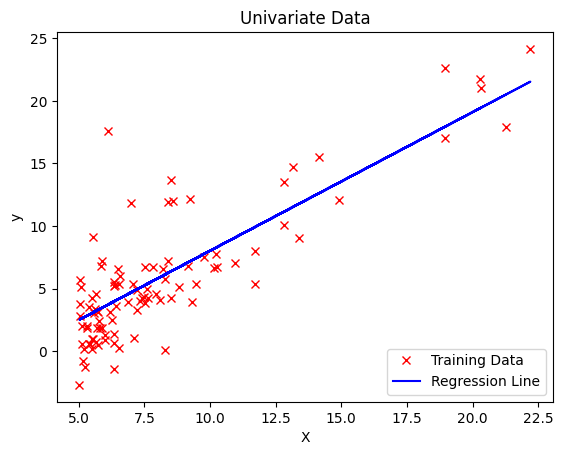

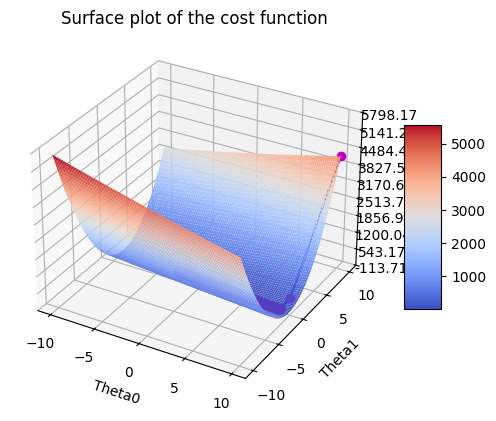

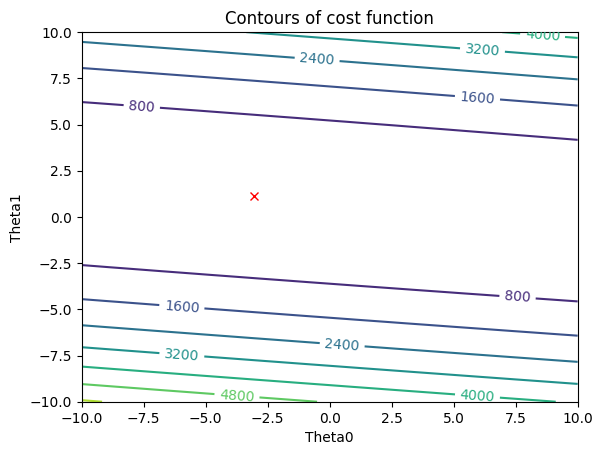

In [33]:

'''
    TEST SCRIPT FOR UNIVARIATE LINEAR REGRESSION
'''

import numpy as np

# Matplotlib provides matlab like plotting tools in python
import matplotlib.pyplot as plt

# our linear regression class
#from linreg import LinearRegression

# All the modules needed for 3d surface plots
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter


#------------------------------------------------------------------------------------------------
# Plotting tools already written for you.
# Feel free edit and experiment.
def plotData1DHelper(X, y):
    plt.clf()
    plt.title("Univariate Data")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.plot(X, y, 'rx', label='Training Data')


def plotData1D(X, y):
    '''
        This function is to plot y vs X where the number of predictors of X is 1.
        Input
        X - n*1 matrix or vector of length n
        y - n*1 matrix or vector of length n
        to_block - boolean flag which when set stops the program execution until the
            plot is closed
    '''
    plotData1DHelper(X, y)
    plt.show()


def plotRegLine1D( lr_model, X, y):
    '''
        Plots the y vs X and also the regressed line according to the theta computed.
        Input
        X - n*2 matrix or vector of length n ( the second dimension is a column of ones for the bias term)
        y - n*1 matrix or vector of length n
        lr_model - linear regression trained model
    '''
    plotData1DHelper(X[:,1], y)
    plt.plot(X[:,1],X*lr_model.theta,'b-', label='Regression Line')
    plt.legend(loc='lower right')
    plt.show()


def visualizeObjective(lr_model,t1_vals,t2_vals, X, y):
    '''
        The function does the surface plot of the objective for a
        univariate regression problem with a bias term, so over 2 parameters.
        Search over the space of theta1, theta2.

        It also plots the gradient descent steps as blue points on the surface plot.
        Finally it plots a contour plot of the same

        lr_model - object of class LinReg (already trained)
        t1_vals, t2_vals - values over which the objective function should be plotted
                        List of numbers
        X - n*2 matrix or vector of length n ( the second dimension is a column of ones for the bias term)
        y - n*1 matrix or vector of length n
    '''
    T1,T2 = np.meshgrid(t1_vals, t2_vals)
    n,p = T1.shape

    # Compute the objective function over the space
    Z = np.zeros(T1.shape)
    for i in range(n):
        for j in range(p):
            Z[i,j] = lr_model.computeCost(X,y, np.matrix([T1[i,j],T2[i,j]]).T )

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(T1, T2, Z, rstride=1, cstride=1, cmap=cm.coolwarm,
        linewidth=0)

    ax.zaxis.set_major_locator(LinearLocator(10))
    ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

    fig.colorbar(surf, shrink=0.5, aspect=5)

    # If the history of the objective function plot the path taken by the gradient descent
    if lr_model.JHist !=None:

        for ii in range(len(lr_model.JHist)-1):
            t1 = lr_model.JHist[ii][1].tolist()
            t2 = lr_model.JHist[ii+1][1].tolist()

            J1 = lr_model.JHist[ii][0]
            J2 = lr_model.JHist[ii+1][0]
            J1 = np.squeeze(np.array(J1))
            J2 = np.squeeze(np.array(J2))

            x_pts = [t1[0][0], t2[0][0]]
            y_pts = [t1[1][0], t2[1][0]]
            J_pts = [J1, J2]
            ax.plot3D(x_pts, y_pts, J_pts, 'b-')

        for J, t in lr_model.JHist:
            J = [np.squeeze(np.array(J))]
            t0 = [np.squeeze(np.array(t[0][0]))]
            t1 = [np.squeeze(np.array(t[1][0]))]
            ax.plot3D(t0, t1, J, 'mo')

    plt.title('Surface plot of the cost function')
    plt.xlabel('Theta0')
    plt.ylabel('Theta1')
    plt.show()

    # Contour plot
    plt.figure()
    plt.clf()
    CS = plt.contour(T1, T2, Z)
    plt.clabel(CS, inline=1, fontsize=10)
    plt.title('Contours of cost function')
    plt.xlabel("Theta0")
    plt.ylabel("Theta1")

    plt.plot(lr_model.theta[0][0],lr_model.theta[1][0], 'rx')
    plt.show()


if __name__ == "__main__":
    '''
        Main function to test univariate linear regression
    '''
    # load the data
    filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/univariateData.dat"
    file = open(filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.ones((d+1,1)))*10  # note that we really should be initializing this to be near zero, but starting it near [10,10] works better to visualize gradient descent for this particular problem
    n_iter = 1500
    alpha = 0.01

    # Instantiate objects
    lr_model = LinearRegression(init_theta=init_theta, alpha=alpha, n_iter=n_iter)
    plotData1D(X[:,1],y)
    lr_model.fit(X,y)
    plotRegLine1D(lr_model, X, y)

    # Visualize the objective function convex shape
    theta1_vals = np.linspace(-10, 10, 100)
    theta2_vals = np.linspace(-10, 10, 100)
    visualizeObjective(lr_model,theta1_vals, theta2_vals, X, y)

# 4) Linreg(High speed)

In [34]:
'''

    TEMPLATE FOR MACHINE LEARNING HOMEWORK

'''
import numpy as np
from numpy import linalg as LA
import matplotlib.pyplot as plt


class LinearRegression:

    def __init__(self, init_theta=None, alpha=0.01, n_iter=100):
        '''
        Constructor
        '''
        self.alpha = alpha
        self.n_iter = n_iter
        self.theta = init_theta
        self.JHist = None

    def gradientDescent(self, X, y, theta):
        '''
        Fits the model via gradient descent
        Arguments:
            X is a n-by-d numpy matrix
            y is an n-dimensional numpy vector
            theta is a d-dimensional numpy vector
        Returns:
            the final theta found by gradient descent
        '''
        n,d = X.shape
        self.JHist = []
        for i in range(self.n_iter):
            self.JHist.append((self.computeCost(X, y, theta), theta))
            print("Iteration: ", i+1, " Cost: ", self.JHist[i][0], " Theta: ", theta)
            # TODO:  add update equation here
            ##################################
            yp = np.matmul(X,theta)
            error = yp - y
            theta = theta - (self.alpha/n) * np.matmul(X.T,error)
            ##################################

        return theta

    def computeCost(self, X, y, theta):
        '''
        Computes the objective function
        Arguments:
          X is a n-by-d numpy matrix
          y is an n-dimensional numpy vector
          theta is a d-dimensional numpy vector
        Returns:
          a scalar value of the cost
              ** make certain you don't return a matrix with just one value! **
        '''
        # TODO: add objective (cost) equation here
        ###########################################
        m = X.shape[0]
        y_pred = np.matmul(X,theta)
        error = y_pred - y

        # Matrix multiplcation does both sum and square
        J = (1/(2*m))*np.matmul(error.T,error)
        return J.item()
        ###########################################

    def fit(self, X, y):
        '''
        Trains the model
        Arguments:
            X is a n-by-d numpy matrix
            y is an n-dimensional numpy vector
        '''
        n = len(y)
        n,d = X.shape
        if self.theta is None:
            self.theta = np.matrix(np.zeros((d,1)))
        self.theta = self.gradientDescent(X,y,self.theta)

    def predict(self, X):
        '''
        Used the model to predict values for each instance in X
        Arguments:
            X is a n-by-d numpy matrix
        Returns:
            an n-dimensional numpy vector of the predictions
        '''
        # TODO:  add prediction function here
        ########################################
        return X.dot(self.theta)
        ########################################

#TEST UNIVARIATE (high speed)
TEST SCRIPT FOR UNIVARIATE LINEAR REGRESSION

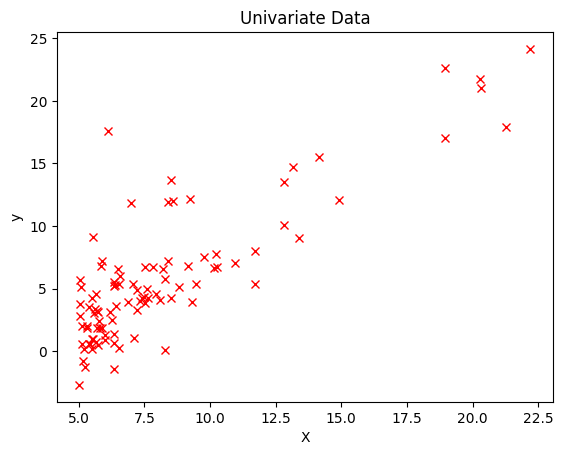

Iteration:  1  Cost:  4256.570027009518  Theta:  [[10.]
 [10.]]
Iteration:  2  Cost:  153.41562305090994  Theta:  [[9.14241135]
 [1.69691422]]
Iteration:  3  Cost:  23.704502028188692  Theta:  [[8.97091378]
 [0.22284515]]
Iteration:  4  Cost:  19.5533596506997  Theta:  [[ 8.92141228]
 [-0.03727971]]
Iteration:  5  Cost:  19.37006882101463  Theta:  [[ 8.89363145]
 [-0.08161346]]
Iteration:  6  Cost:  19.31234880158314  Theta:  [[ 8.86974598]
 [-0.08759093]]
Iteration:  7  Cost:  19.258783829512506  Theta:  [[ 8.84658712]
 [-0.08675349]]
Iteration:  8  Cost:  19.205536524093198  Theta:  [[ 8.82359151]
 [-0.08470805]]
Iteration:  9  Cost:  19.152484953790523  Theta:  [[ 8.80065895]
 [-0.08245128]]
Iteration:  10  Cost:  19.09962459672961  Theta:  [[ 8.77777157]
 [-0.08016036]]
Iteration:  11  Cost:  19.046954643559957  Theta:  [[ 8.75492613]
 [-0.07786677]]
Iteration:  12  Cost:  18.99447440464646  Theta:  [[ 8.732122  ]
 [-0.07557611]]
Iteration:  13  Cost:  18.94218319652887  Theta:  [[

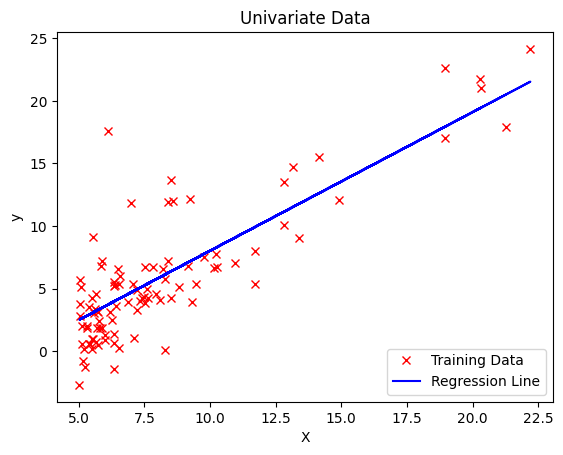

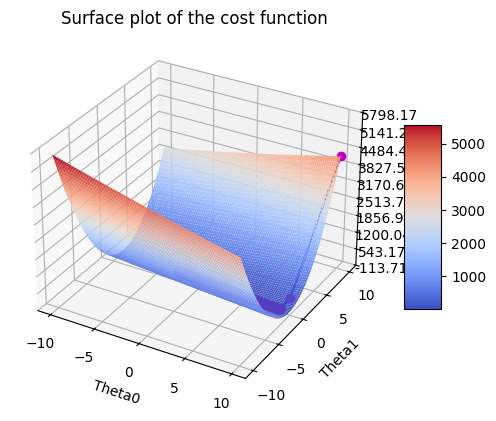

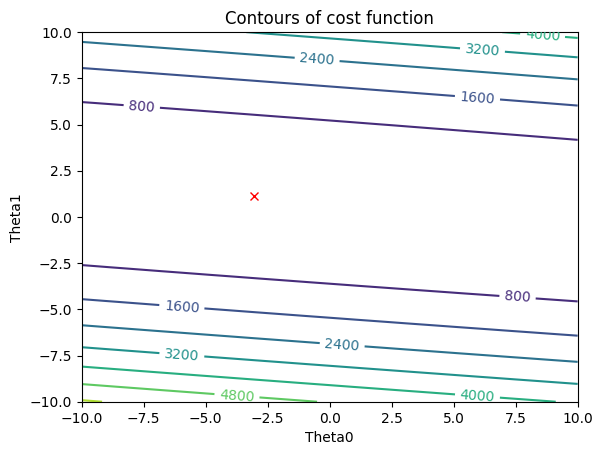

In [35]:

'''
    TEST SCRIPT FOR UNIVARIATE LINEAR REGRESSION
'''

import numpy as np

# Matplotlib provides matlab like plotting tools in python
import matplotlib.pyplot as plt

# our linear regression class
#from linreg import LinearRegression

# All the modules needed for 3d surface plots
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter


#------------------------------------------------------------------------------------------------
# Plotting tools already written for you.
# Feel free edit and experiment.
def plotData1DHelper(X, y):
    plt.clf()
    plt.title("Univariate Data")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.plot(X, y, 'rx', label='Training Data')


def plotData1D(X, y):
    '''
        This function is to plot y vs X where the number of predictors of X is 1.
        Input
        X - n*1 matrix or vector of length n
        y - n*1 matrix or vector of length n
        to_block - boolean flag which when set stops the program execution until the
            plot is closed
    '''
    plotData1DHelper(X, y)
    plt.show()


def plotRegLine1D( lr_model, X, y):
    '''
        Plots the y vs X and also the regressed line according to the theta computed.
        Input
        X - n*2 matrix or vector of length n ( the second dimension is a column of ones for the bias term)
        y - n*1 matrix or vector of length n
        lr_model - linear regression trained model
    '''
    plotData1DHelper(X[:,1], y)
    plt.plot(X[:,1],X*lr_model.theta,'b-', label='Regression Line')
    plt.legend(loc='lower right')
    plt.show()


def visualizeObjective(lr_model,t1_vals,t2_vals, X, y):
    '''
        The function does the surface plot of the objective for a
        univariate regression problem with a bias term, so over 2 parameters.
        Search over the space of theta1, theta2.

        It also plots the gradient descent steps as blue points on the surface plot.
        Finally it plots a contour plot of the same

        lr_model - object of class LinReg (already trained)
        t1_vals, t2_vals - values over which the objective function should be plotted
                        List of numbers
        X - n*2 matrix or vector of length n ( the second dimension is a column of ones for the bias term)
        y - n*1 matrix or vector of length n
    '''
    T1,T2 = np.meshgrid(t1_vals, t2_vals)
    n,p = T1.shape

    # Compute the objective function over the space
    Z = np.zeros(T1.shape)
    for i in range(n):
        for j in range(p):
            Z[i,j] = lr_model.computeCost(X,y, np.matrix([T1[i,j],T2[i,j]]).T )

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(T1, T2, Z, rstride=1, cstride=1, cmap=cm.coolwarm,
        linewidth=0)

    ax.zaxis.set_major_locator(LinearLocator(10))
    ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

    fig.colorbar(surf, shrink=0.5, aspect=5)

    # If the history of the objective function plot the path taken by the gradient descent
    if lr_model.JHist !=None:

        for ii in range(len(lr_model.JHist)-1):
            t1 = lr_model.JHist[ii][1].tolist()
            t2 = lr_model.JHist[ii+1][1].tolist()

            J1 = lr_model.JHist[ii][0]
            J2 = lr_model.JHist[ii+1][0]
            J1 = np.squeeze(np.array(J1))
            J2 = np.squeeze(np.array(J2))

            x_pts = [t1[0][0], t2[0][0]]
            y_pts = [t1[1][0], t2[1][0]]
            J_pts = [J1, J2]
            ax.plot3D(x_pts, y_pts, J_pts, 'b-')

        for J, t in lr_model.JHist:
            J = [np.squeeze(np.array(J))]
            t0 = [np.squeeze(np.array(t[0][0]))]
            t1 = [np.squeeze(np.array(t[1][0]))]
            ax.plot3D(t0, t1, J, 'mo')

    plt.title('Surface plot of the cost function')
    plt.xlabel('Theta0')
    plt.ylabel('Theta1')
    plt.show()

    # Contour plot
    plt.figure()
    plt.clf()
    CS = plt.contour(T1, T2, Z)
    plt.clabel(CS, inline=1, fontsize=10)
    plt.title('Contours of cost function')
    plt.xlabel("Theta0")
    plt.ylabel("Theta1")

    plt.plot(lr_model.theta[0][0],lr_model.theta[1][0], 'rx')
    plt.show()


if __name__ == "__main__":
    '''
        Main function to test univariate linear regression
    '''
    # load the data
    filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/univariateData.dat"
    file = open(filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.ones((d+1,1)))*10  # note that we really should be initializing this to be near zero, but starting it near [10,10] works better to visualize gradient descent for this particular problem
    n_iter = 1500
    alpha = 0.01

    # Instantiate objects
    lr_model = LinearRegression(init_theta=init_theta, alpha=alpha, n_iter=n_iter)
    plotData1D(X[:,1],y)
    lr_model.fit(X,y)
    plotRegLine1D(lr_model, X, y)

    # Visualize the objective function convex shape
    theta1_vals = np.linspace(-10, 10, 100)
    theta2_vals = np.linspace(-10, 10, 100)
    visualizeObjective(lr_model,theta1_vals, theta2_vals, X, y)

# 5) Test linreg multivariate
  TEST SCRIPT FOR MULTIVARIATE LINEAR REGRESSION

In [36]:
'''
    TEST SCRIPT FOR MULTIVARIATE LINEAR REGRESSION
'''

import numpy as np
from numpy.linalg import *

# our linear regression class
#from linreg import LinearRegression


if __name__ == "__main__":
    '''
        Main function to test multivariate linear regression
    '''

    # load the data
    filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
    file = open(filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std

    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.random.randn((d+1))).T
    n_iter = 2000
    alpha = 0.01

    # Instantiate objects
    lr_model = LinearRegression(init_theta = init_theta, alpha = alpha, n_iter = n_iter)
    lr_model.fit(X,y)

Streaming output truncated to the last 5000 lines.
 [ 95815.77687277]
 [  6506.05043487]]
Iteration:  335  Cost:  2191578485.529737  Theta:  [[328550.58961822]
 [ 95878.82869023]
 [  6451.54122101]]
Iteration:  336  Cost:  2189491471.0149074  Theta:  [[328669.21031778]
 [ 95941.55522325]
 [  6397.22402979]]
Iteration:  337  Cost:  2187438427.7444797  Theta:  [[328786.64481035]
 [ 96003.95864939]
 [  6343.09876247]]
Iteration:  338  Cost:  2185418745.2201877  Theta:  [[328902.90495799]
 [ 96066.04112501]
 [  6289.1653091 ]]
Iteration:  339  Cost:  2183431824.5438786  Theta:  [[329018.00250416]
 [ 96127.80478553]
 [  6235.42354877]]
Iteration:  340  Cost:  2181477078.190652  Theta:  [[329131.94907486]
 [ 96189.25174568]
 [  6181.87334979]]
Iteration:  341  Cost:  2179553929.786531  Theta:  [[329244.75617986]
 [ 96250.38409978]
 [  6128.51456997]]
Iteration:  342  Cost:  2177661813.8905234  Theta:  [[329356.4352138 ]
 [ 96311.20392201]
 [  6075.34705683]]
Iteration:  343  Cost:  217580017

# 6) Model evaluation

In [37]:
import numpy as np
from numpy.linalg import *
#from linreg import LinearRegression

## Implementation Essential Functions

In [38]:
def Train_model(dataPath, alpha, n_iter):

    # load the data
    file = open(dataPath, 'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:, :-1])
    y = np.matrix((allData[:, -1])).T

    n, d = X.shape

    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std

    # Add a row of ones for the bias term
    X = np.c_[np.ones((n, 1)), X]

    init_theta = np.matrix(np.random.randn((d + 1))).T

    lr_model = LinearRegression(init_theta=init_theta, alpha=alpha, n_iter=n_iter)
    lr_model.fit(X, y)
    return lr_model.theta, lr_model.JHist[-1][0] * 2


def calculate_loss(y, y_predicted):

    # TODO : implement a function to calculate MSE and RMSE
    #################################################################
    MSE_loss = np.square(np.subtract(y, y_predicted)).mean()
    RMSE_loss = np.sqrt(MSE_loss)
    #################################################################
    return MSE_loss, RMSE_loss


def model_evaluation(filePath, tetha, alpha, n_iter):

    # load the data
    file = open(filePath, 'rb')
    allData = np.load(file)['arr_0']

    X = np.matrix(allData[:, :-1])
    y = np.matrix((allData[:, -1])).T

    n, d = X.shape

    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std

    # Add a row of ones for the bias term
    X = np.c_[np.ones((n, 1)), X]

    model = LinearRegression(init_theta=tetha, alpha=alpha, n_iter=n_iter)
    return calculate_loss(y, model.predict(X))

## Loss of multivariate reg

In [39]:
test_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz"
train_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
init_theta = Train_model(train_filePath, alpha, n_iter)[0]
loss = model_evaluation(test_filePath, init_theta, alpha, n_iter)
print('MSE: ', loss[0])
print('RMSE: ', loss[1])

Streaming output truncated to the last 5000 lines.
Iteration:  335  Cost:  2191573897.0950603  Theta:  [[328550.59258192]
 [ 95879.21993051]
 [  6451.15474466]]
Iteration:  336  Cost:  2189486923.307923  Theta:  [[328669.21325185]
 [ 95941.94471526]
 [  6396.83922738]]
Iteration:  337  Cost:  2187433920.3983912  Theta:  [[328786.64771507]
 [ 96004.34640125]
 [  6342.71562706]]
Iteration:  338  Cost:  2185414277.87162  Theta:  [[328902.90783367]
 [ 96066.42714479]
 [  6288.78383376]]
Iteration:  339  Cost:  2183427396.832835  Theta:  [[329018.00535108]
 [ 96128.18908125]
 [  6235.04372659]]
Iteration:  340  Cost:  2181472689.7604933  Theta:  [[329131.95189331]
 [ 96189.63432532]
 [  6181.49517391]]
Iteration:  341  Cost:  2179549580.2839265  Theta:  [[329244.75897012]
 [ 96250.76497128]
 [  6128.13803353]]
Iteration:  342  Cost:  2177657502.9654317  Theta:  [[329356.43797616]
 [ 96311.58309327]
 [  6074.97215299]]
Iteration:  343  Cost:  2175795903.0866556  Theta:  [[329467.00019215]
 [

-------------------------------------

# Hyper-Parameter Tuning and Loss Calculation

###effect of n_iter

In [40]:
if __name__ == "__main__":
    '''
        Main function to test univariate linear regression
    '''
    # load the data
    train_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
    file = open(train_filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    ####################################################
    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std
    ####################################################
    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.ones((d+1,1)))*10  # note that we really should be initializing this to be near zero, but starting it near [10,10] works better to visualize gradient descent for this particular problem
    n_iter = np.arange(10, 3000, 10)
    alpha = 0.01

    test_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz"

    mse_list = []
    for iter in n_iter:
      # Instantiate objects
      lr_model = LinearRegression(init_theta=init_theta, alpha=alpha, n_iter=iter)
      lr_model.fit(X,y)

      loss = model_evaluation(test_filePath, lr_model.theta, alpha, iter)
      mse_list.append(loss[0])
      print('MSE: ', loss[0])
      print('RMSE: ', loss[1])



Streaming output truncated to the last 5000 lines.
Iteration:  1325  Cost:  2043292609.3641357  Theta:  [[340412.09334745]
 [109278.85812713]
 [ -6409.41660532]]
Iteration:  1326  Cost:  2043292499.0801897  Theta:  [[340412.09900972]
 [109279.60151177]
 [ -6410.1599885 ]]
Iteration:  1327  Cost:  2043292389.7647161  Theta:  [[340412.10461536]
 [109280.34162526]
 [ -6410.90010055]]
Iteration:  1328  Cost:  2043292281.4092078  Theta:  [[340412.11016495]
 [109281.078482  ]
 [ -6411.63695588]]
Iteration:  1329  Cost:  2043292174.0052345  Theta:  [[340412.11565905]
 [109281.81209632]
 [ -6412.3705688 ]]
Iteration:  1330  Cost:  2043292067.5444412  Theta:  [[340412.1210982 ]
 [109282.54248249]
 [ -6413.1009536 ]]
Iteration:  1331  Cost:  2043291962.018543  Theta:  [[340412.12648297]
 [109283.26965472]
 [ -6413.82812448]]
Iteration:  1332  Cost:  2043291857.4193332  Theta:  [[340412.13181388]
 [109283.99362714]
 [ -6414.55209557]]
Iteration:  1333  Cost:  2043291753.7386675  Theta:  [[340412.

In [41]:
loss_opt = np.argmin(mse_list)
iter_opt = n_iter[loss_opt]
min_loss = min(mse_list)
print('loss_opt: ', loss_opt)
print('iter_opt: ', iter_opt)
print('min_loss: ', min_loss)

loss_opt:  20
iter_opt:  210
min_loss:  2598961047.7287035


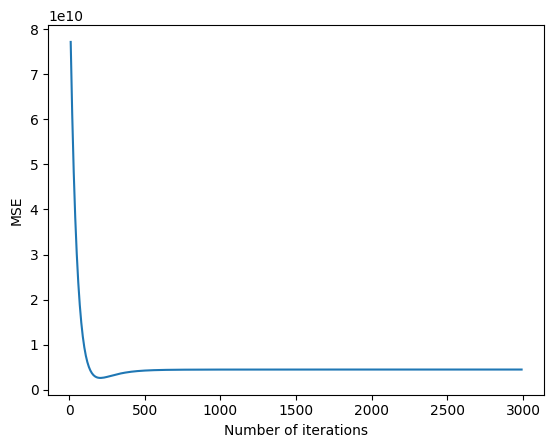

In [42]:
plt.figure()
plt.plot(n_iter, mse_list)
plt.xlabel('Number of iterations')
plt.ylabel('MSE')
plt.show()

###effect of alpha

In [43]:
if __name__ == "__main__":
    '''
        Main function to test univariate linear regression
    '''
    # load the data
    train_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
    file = open(train_filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    ####################################################
    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std
    ####################################################
    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.ones((d+1,1)))*10  # note that we really should be initializing this to be near zero, but starting it near [10,10] works better to visualize gradient descent for this particular problem
    n_iter = 210
    alpha = np.arange(0, 1, 0.01)

    test_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz"

    mse_list = []
    for a in alpha:
      # Instantiate objects
      lr_model = LinearRegression(init_theta=init_theta, alpha=a, n_iter=n_iter)
      lr_model.fit(X,y)

      loss = model_evaluation(test_filePath, lr_model.theta, a, n_iter)
      mse_list.append(loss[0])
      print('MSE: ', loss[0])
      print('RMSE: ', loss[1])



Streaming output truncated to the last 5000 lines.
 [ -6573.27692338]]
Iteration:  20  Cost:  2043280054.6476507  Theta:  [[340412.65957447]
 [109444.77166124]
 [ -6575.31602671]]
Iteration:  21  Cost:  2043280052.035601  Theta:  [[340412.65957447]
 [109445.98897275]
 [ -6576.55345794]]
Iteration:  22  Cost:  2043280051.1103537  Theta:  [[340412.65957447]
 [109446.72384491]
 [ -6577.2795746 ]]
Iteration:  23  Cost:  2043280050.7826064  Theta:  [[340412.65957447]
 [109447.15670808]
 [ -6577.7162479 ]]
Iteration:  24  Cost:  2043280050.66651  Theta:  [[340412.65957447]
 [109447.41629804]
 [ -6577.97417981]]
Iteration:  25  Cost:  2043280050.625387  Theta:  [[340412.65957447]
 [109447.56994397]
 [ -6578.12854727]]
Iteration:  26  Cost:  2043280050.6108184  Theta:  [[340412.65957447]
 [109447.66176111]
 [ -6578.22005042]]
Iteration:  27  Cost:  2043280050.6056585  Theta:  [[340412.65957447]
 [109447.71624614]
 [ -6578.27467209]]
Iteration:  28  Cost:  2043280050.6038318  Theta:  [[340412.6

In [44]:
loss_opt = np.argmin(mse_list)
alpha_opt = alpha[loss_opt]
min_loss = min(mse_list)
print('loss_opt: ', loss_opt)
print('alpha_opt: ', alpha_opt)
print('min_loss: ', min_loss)

loss_opt:  1
alpha_opt:  0.01
min_loss:  2598961047.7287035


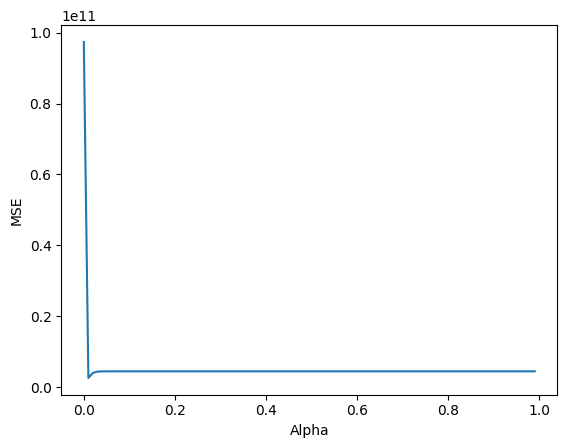

In [45]:
plt.figure()
plt.plot(alpha, mse_list)
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.show()

###effect of alpha & n_iter

In [46]:
if __name__ == "__main__":
    '''
        Main function to test univariate linear regression
    '''
    # load the data
    train_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
    file = open(train_filePath,'r')
    allData = np.loadtxt(file, delimiter=',')

    X = np.matrix(allData[:,:-1])
    y = np.matrix((allData[:,-1])).T

    n,d = X.shape

    ####################################################
    # Standardize
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X = (X - mean) / std
    ####################################################
    # Add a row of ones for the bias term
    X = np.c_[np.ones((n,1)), X]

    # initialize the model
    init_theta = np.matrix(np.ones((d+1,1)))*10  # note that we really should be initializing this to be near zero, but starting it near [10,10] works better to visualize gradient descent for this particular problem
    alpha_list = np.arange(0.01,0.25,0.03)
    n_iter = np.arange(100,300,10)

    test_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz"

    mse_list = []
    for a in alpha_list:
      iner_lst = []
      for iter in n_iter:
        # Instantiate objects
        lr_model = LinearRegression(init_theta=init_theta, alpha=a, n_iter=iter)
        lr_model.fit(X,y)

        loss = model_evaluation(test_filePath, lr_model.theta, a, iter)
        print('MSE: ', loss[0])
        print('RMSE: ', loss[1])
        iner_lst.append(loss[0])
      mse_list.append(iner_lst)




Streaming output truncated to the last 5000 lines.
Iteration:  159  Cost:  2043280050.6028438  Theta:  [[340412.65957447]
 [109447.79048775]
 [ -6578.34887227]]
Iteration:  160  Cost:  2043280050.6028407  Theta:  [[340412.65957447]
 [109447.79106684]
 [ -6578.34945136]]
Iteration:  161  Cost:  2043280050.6028392  Theta:  [[340412.65957447]
 [109447.79158987]
 [ -6578.34997439]]
Iteration:  162  Cost:  2043280050.6028364  Theta:  [[340412.65957447]
 [109447.79206227]
 [ -6578.35044679]]
Iteration:  163  Cost:  2043280050.6028352  Theta:  [[340412.65957447]
 [109447.79248893]
 [ -6578.35087345]]
Iteration:  164  Cost:  2043280050.6028337  Theta:  [[340412.65957447]
 [109447.79287429]
 [ -6578.35125881]]
Iteration:  165  Cost:  2043280050.6028326  Theta:  [[340412.65957447]
 [109447.79322235]
 [ -6578.35160687]]
Iteration:  166  Cost:  2043280050.6028318  Theta:  [[340412.65957447]
 [109447.79353671]
 [ -6578.35192123]]
Iteration:  167  Cost:  2043280050.602831  Theta:  [[340412.65957447]

In [47]:
#min_index = np.unravel_index(mse_list.argmin(), mse_list.shape)
min_index = np.unravel_index(np.argmin(mse_list), np.shape(mse_list))
print('min index: ', min_index)

min index:  (np.int64(0), np.int64(11))


In [48]:
alpha_opt = alpha_list[min_index[0]]
iter_opt = n_iter[min_index[1]]
min_loss = mse_list[min_index[0]][min_index[1]]
min_rmse = np.sqrt(min_loss)

print('alpha_opt: ', alpha_opt)
print('iter_opt: ', iter_opt)
print('min MSE: ', min_loss)
print('min RMSE: ', min_rmse)

alpha_opt:  0.01
iter_opt:  210
min MSE:  2598961047.7287035
min RMSE:  50980.006352772296


# 7) sklearn library

In [49]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing, svm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [50]:
'''
    TEST SCRIPT FOR MULTIVARIATE LINEAR REGRESSION
'''

import numpy as np
from numpy.linalg import *

# our linear regression class
#from linreg import LinearRegression


if __name__ == "__main__":
    '''
        Main function to test multivariate linear regression
    '''

    # load the data
    filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/multivariateData.dat"
    test_filePath = "/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz"
    file = open(filePath,'r')
    allData = np.loadtxt(file, delimiter=',')


    X = np.array(allData[:,:-1])
    y = np.array((allData[:,-1])).T

    n,d = X.shape


    X_mean = X.mean(axis=0)
    X_std = X.std(axis=0)
    X = (X - X_mean) / X_std

    # Instantiate objects
    lr_model = LinearRegression()
    lr_model.fit(X,y)


In [51]:
import numpy
test_data = numpy.load("/content/drive/MyDrive/ML/ML/تمرین اول/data/holdout.npz")
print(test_data.files)

['arr_0']


In [52]:
X_test = np.array(test_data['arr_0'][:,:-1])
y_test = np.array((test_data['arr_0'][:,-1])).T

print(X_test.shape)
print(y_test.shape)

(20, 2)
(20,)


In [53]:
X_test = (X_test - X_mean) / X_std
print(X_test.shape)

(20, 2)


In [54]:
y_pred = lr_model.predict(X_test).reshape(-1, 1)
print(y_pred.shape)


(20, 1)


In [55]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

mae = mean_absolute_error(y_true=y_test,y_pred=y_pred)
#squared True returns MSE value, False returns RMSE value.
mse = mean_squared_error(y_true=y_test,y_pred=y_pred) #default=True
rmse = np.sqrt(mse)

print("Root Mean Square Error (RMSE):", rmse)
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)

Root Mean Square Error (RMSE): 48020.90935978906
MAE: 38658.81514168994
MSE: 2306007735.741077
RMSE: 48020.90935978906


## Conclusion and Model Comparison

In this exercise, Multivariate Linear Regression was implemented from scratch using Gradient Descent. The model was trained and evaluated by experimenting with different values of the learning rate (`alpha`) and the number of iterations (`n_iter`).

The best hyperparameters found within the tested ranges were:

- **Best alpha:** 0.01
- **Best number of iterations:** 210
- **MSE:** 2,598,961,047.73
- **RMSE:** 50,980.01

Next, the built-in `LinearRegression` model from Scikit-learn was used. Its evaluation results were:

- **MSE:** 2,306,007,735.74
- **RMSE:** 48,020.91
- **MAE:** 38,658.82

### Comparison

Based on the obtained results, Scikit-learn achieved lower MSE and RMSE values than the custom implementation. Its RMSE was approximately 5.8% lower, indicating smaller prediction errors in this evaluation.

However, this comparison is not completely fair because the two implementations used different standardization procedures for the test data. For a reliable comparison, both models should use the training data's mean and standard deviation to standardize the test set.

Overall, this exercise demonstrated how Linear Regression and Gradient Descent can be implemented from scratch, how hyperparameters affect model performance, and how the custom implementation compares with Scikit-learn.